In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

%matplotlib inline

In [5]:
df = pd.read_csv(r'C:\Users\kelvi\Downloads\National_River_Toxin.csv')

In [14]:
df.head(30)

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925
5,2018-01-08,Amazon,6.816453,20.009290,2.317695,0.468534,2.779205,14.375101,NaN,8.801352
6,2018-01-08,Nile,7.713234,19.385417,3.281072,NaN,2.969543,8.043222,0.400075,7.887773
7,2018-01-08,Yangtze,6.997987,17.460123,5.077893,0.668969,6.103828,9.058403,0.667304,6.697805
8,2018-01-08,Mississippi,8.053054,20.636471,4.150143,0.629782,3.154285,8.761829,0.562562,8.981253
9,2018-01-08,Danube,7.552935,22.521190,2.779919,0.314452,2.232550,10.508599,0.534827,10.050782


In [7]:
df.shape

(1305, 10)

In [8]:
df.isnull().sum()

Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64

In [9]:
df.dropna()

,Date,River_System,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
0,2018-01-01,Amazon,7.030015,19.136212,2.500401,0.465454,3.578886,11.627614,0.522167,7.830196
1,2018-01-01,Nile,7.421766,21.406824,3.469443,0.859716,5.352155,10.538171,0.510465,8.130328
2,2018-01-01,Yangtze,7.133612,18.419902,3.806935,0.824085,5.277814,7.865033,0.585096,8.120874
3,2018-01-01,Mississippi,7.863001,18.014871,3.438131,0.500597,3.473881,11.143068,0.438248,6.853816
4,2018-01-01,Danube,7.527686,16.622289,2.188210,0.424178,2.454209,8.043467,0.422244,8.197925
...,...,...,...,...,...,...,...,...,...,...
1299,2022-12-19,Danube,7.571116,18.117695,1.849847,0.468266,2.430705,10.405424,0.607075,8.920067
1301,2022-12-26,Nile,7.214448,21.005255,1.395876,0.743100,4.243743,7.766917,0.624352,7.907600
1302,2022-12-26,Yangtze,6.852077,18.841392,3.677048,0.634460,5.958020,9.855321,0.567842,10.983113
1303,2022-12-26,Mississippi,7.923046,18.886274,3.229030,0.526015,3.904349,10.859932,0.498410,8.284721


In [10]:
df.columns

Index(['Date', 'River_System', 'pH_Level', 'Temperature', 'Lead', 'Mercury',
       'Arsenic', 'Nitrates', 'Phosphates', 'Dissolved_Oxygen'],
      dtype='object')

In [11]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1300    False
1301    False
1302    False
1303    False
1304    False
Length: 1305, dtype: bool

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1305 non-null   object 
 1   River_System      1305 non-null   object 
 2   pH_Level          1278 non-null   float64
 3   Temperature       1278 non-null   float64
 4   Lead              1285 non-null   float64
 5   Mercury           1278 non-null   float64
 6   Arsenic           1279 non-null   float64
 7   Nitrates          1265 non-null   float64
 8   Phosphates        1282 non-null   float64
 9   Dissolved_Oxygen  1284 non-null   float64
dtypes: float64(8), object(2)
memory usage: 102.1+ KB


In [23]:
df['Date'] = pd.to_datetime(df['Date'])

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              1305 non-null   datetime64[ns]
 1   River_System      1305 non-null   object        
 2   pH_Level          1278 non-null   float64       
 3   Temperature       1278 non-null   float64       
 4   Lead              1285 non-null   float64       
 5   Mercury           1278 non-null   float64       
 6   Arsenic           1279 non-null   float64       
 7   Nitrates          1265 non-null   float64       
 8   Phosphates        1282 non-null   float64       
 9   Dissolved_Oxygen  1284 non-null   float64       
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 102.1+ KB


In [31]:
###Calculate the average toxin:
# List of toxin columns
toxins = ['pH_Level', 'Temperature', 'Lead', 'Mercury', 
          'Arsenic', 'Nitrates', 'Phosphates', 'Dissolved_Oxygen']

# Calculate average toxin levels per river
avg_toxins = df.groupby('River_System')[toxins].mean()
avg_overall_toxin = df[toxins].mean()
print(f"Average_Level of Toxin: {avg_overall_toxin}")

avg_toxins


Average_Level of Toxin: pH_Level             7.353247
Temperature         20.041668
Lead                 3.011035
Mercury              0.596108
Arsenic              3.597916
Nitrates            10.038789
Phosphates           0.497162
Dissolved_Oxygen     8.023795
dtype: float64


,pH_Level,Temperature,Lead,Mercury,Arsenic,Nitrates,Phosphates,Dissolved_Oxygen
River_System,,,,,,,,
Amazon,6.984401,20.029672,2.015404,0.491959,3.005612,9.883220,0.504355,8.008012
Danube,7.311050,20.123258,2.539492,0.396511,2.496212,9.987329,0.498761,7.902202
Mississippi,7.803676,19.913761,3.489190,0.598581,3.490920,10.138178,0.502774,8.033731
Nile,7.469010,20.113982,2.989879,0.708797,3.997052,10.240214,0.493598,8.153453
Yangtze,7.193857,20.028194,4.022830,0.791298,4.985871,9.937239,0.486391,8.021728


In [17]:
df['Toxin_Average'] = df[toxins].mean(axis=1)

river_overall_avg = df.groupby('River_System')['Toxin_Average'].mean()
river_overall_avg

River_System
Amazon         6.305167
Danube         6.387459
Mississippi    6.772409
Nile           6.786874
Yangtze        6.916268
Name: Toxin_Average, dtype: float64

In [42]:
# Toxin columns
toxins = ['Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates']

# Create an overall pollution score (mean of toxins per row)
df['Pollution_Score'] = df[toxins].mean(axis=1)

# Average pollution score per river
river_pollution = df.groupby('River_System')['Pollution_Score'].mean()

# Top 5 most polluted rivers
top5_polluted = river_pollution.sort_values(ascending=False).head(5)
top5_polluted

River_System
Yangtze        3.976233
Nile           3.689386
Mississippi    3.650752
Danube         3.175388
Amazon         3.160964
Name: Pollution_Score, dtype: float64

In [20]:
corr = df[['pH_Level'] + toxins].corr()['pH_Level'].drop('pH_Level')
corr

Lead          0.325189
Mercury       0.140751
Arsenic       0.043497
Nitrates      0.084319
Phosphates    0.090934
Name: pH_Level, dtype: float64

<Figure size 1200x600 with 0 Axes>

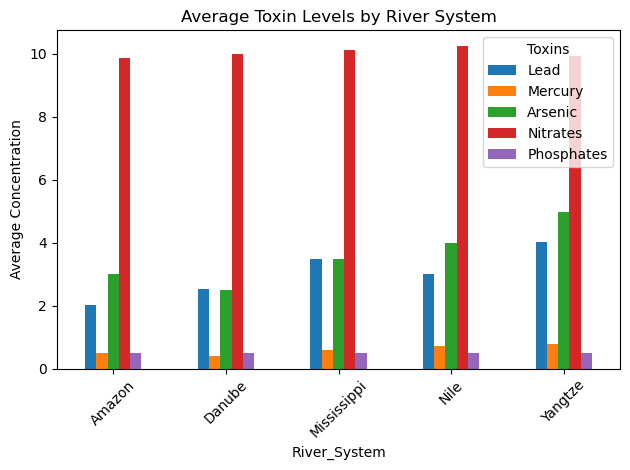

In [21]:
#### create a bar chart of average toxin levels by river system.
avg_toxins = df.groupby('River_System')[toxins].mean()

plt.figure(figsize=(12,6))
avg_toxins.plot(kind='bar')
plt.title('Average Toxin Levels by River System')
plt.ylabel('Average Concentration')
plt.xticks(rotation=45)
plt.legend(title='Toxins')
plt.tight_layout()
plt.show()

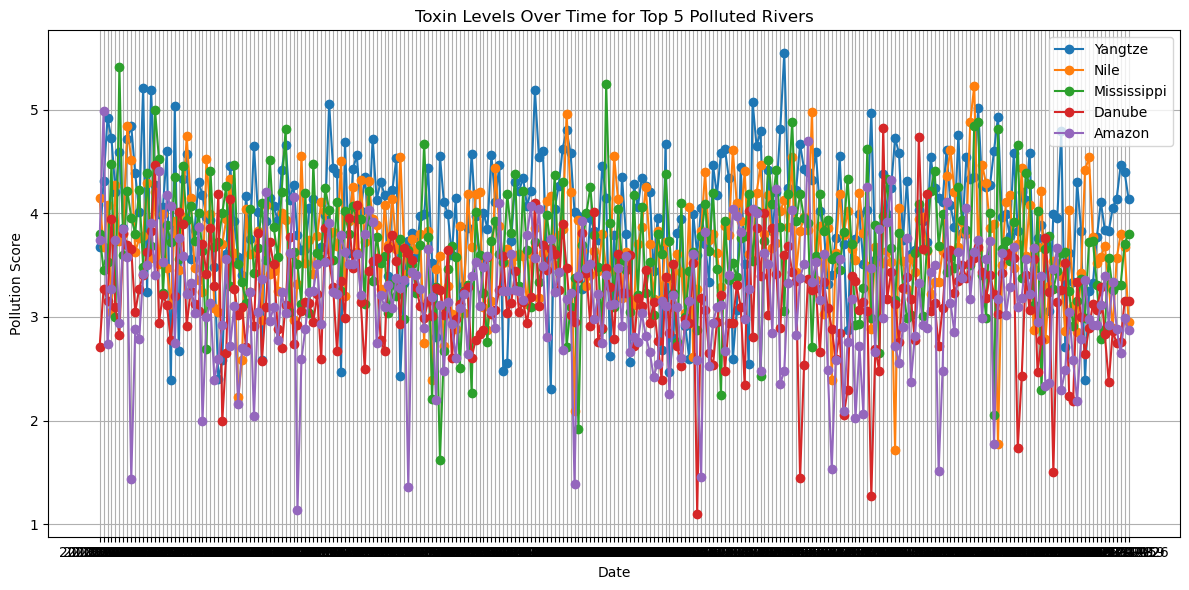

In [22]:
# Create pollution score
df['Pollution_Score'] = df[toxins].mean(axis=1)

# Top 5 polluted rivers
top5 = df.groupby('River_System')['Pollution_Score'].mean().sort_values(ascending=False).head(5).index

df_top5 = df[df['River_System'].isin(top5)]

plt.figure(figsize=(12,6))
for river in top5:
    subset = df_top5[df_top5['River_System'] == river]
    plt.plot(subset['Date'], subset['Pollution_Score'], marker='o', label=river)

plt.title('Toxin Levels Over Time for Top 5 Polluted Rivers')
plt.xlabel('Date')
plt.ylabel('Pollution Score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

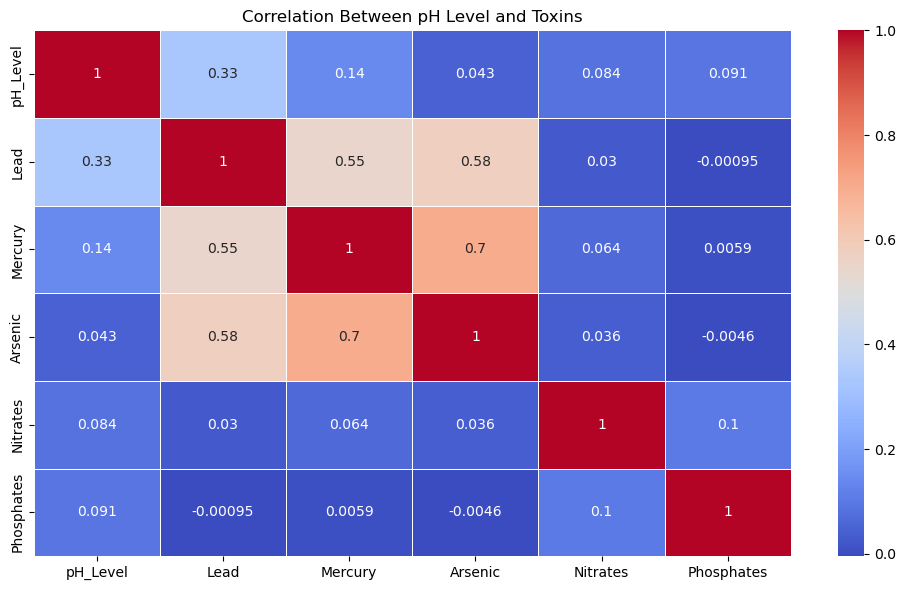

In [23]:
# 3. HEATMAP — Correlation between toxins and pH levels
# ============================================================

corr = df[['pH_Level'] + toxins].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Between pH Level and Toxins')
plt.tight_layout()
plt.show()

In [26]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              1305 non-null   datetime64[ns]
 1   River_System      1305 non-null   object        
 2   pH_Level          1278 non-null   float64       
 3   Temperature       1278 non-null   float64       
 4   Lead              1285 non-null   float64       
 5   Mercury           1278 non-null   float64       
 6   Arsenic           1279 non-null   float64       
 7   Nitrates          1265 non-null   float64       
 8   Phosphates        1282 non-null   float64       
 9   Dissolved_Oxygen  1284 non-null   float64       
 10  Toxin_Average     1305 non-null   float64       
 11  Pollution_Score   1305 non-null   float64       
dtypes: datetime64[ns](1), float64(10), object(1)
memory usage: 122.5+ KB


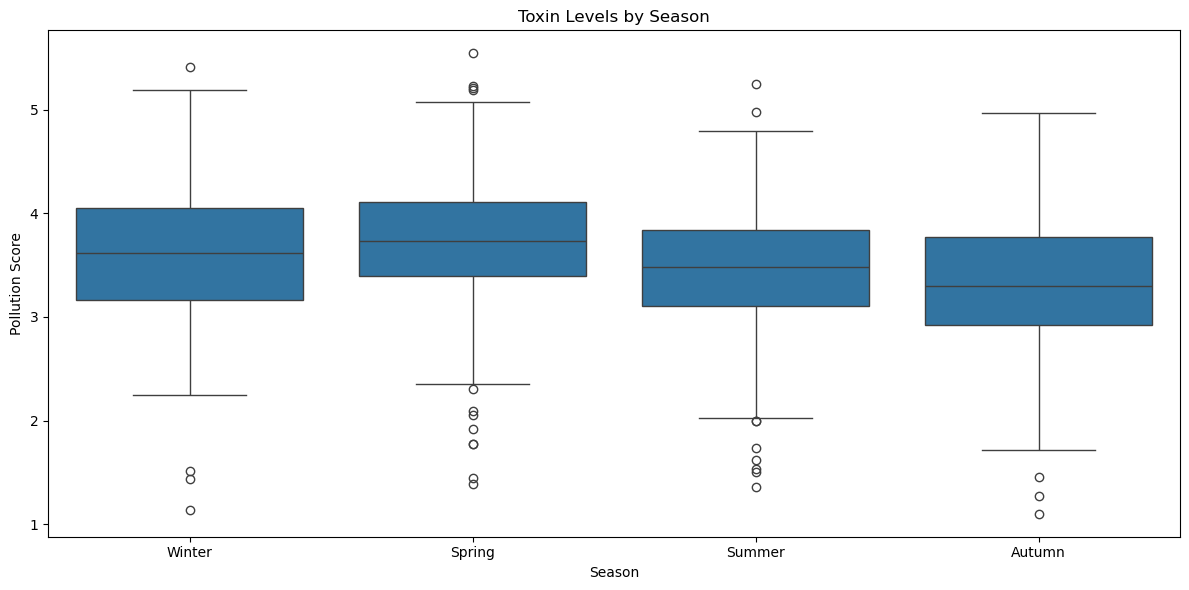

In [28]:
# 4. BOX PLOT — Toxin levels by season
# ============================================================
# Function to map month → season
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['Season'] = df['Date'].dt.month.apply(get_season)

plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='Season', y='Pollution_Score', order=['Winter','Spring','Summer','Autumn'])
plt.title('Toxin Levels by Season')
plt.ylabel('Pollution Score')
plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
from scipy import stats
import statsmodels.api as sm

# Assuming df already loaded and Pollution_Score already created
# toxins = ['Lead', 'Mercury', 'Arsenic', 'Nitrates', 'Phosphates']
# df['Pollution_Score'] = df[toxins].mean(axis=1)

# -----------------------------
# T-TEST: compare two river systems
# -----------------------------
river_a = 'Nile'
river_b = 'Yangtze'

a_scores = df[df['River_System'] == river_a]['Pollution_Score'].dropna()
b_scores = df[df['River_System'] == river_b]['Pollution_Score'].dropna()

t_stat, p_val = stats.ttest_ind(a_scores, b_scores, equal_var=False)
print(f"T-test {river_a} vs {river_b}: t = {t_stat:.3f}, p = {p_val:.4f}")

# -----------------------------
# LINEAR REGRESSION: predict toxin level from pH
# Using overall Pollution_Score as target
# -----------------------------
X = df[['pH_Level']].copy()
X = sm.add_constant(X)  # add intercept
y = df['Pollution_Score']

model = sm.OLS(y, X, missing='drop').fit()
print(model.summary())


T-test Nile vs Yangtze: t = -5.755, p = 0.0000
                            OLS Regression Results                            
Dep. Variable:        Pollution_Score   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     45.39
Date:                Wed, 22 Apr 2026   Prob (F-statistic):           2.44e-11
Time:                        08:03:38   Log-Likelihood:                -1232.0
No. Observations:                1278   AIC:                             2468.
Df Residuals:                    1276   BIC:                             2478.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const

##### 2. High-level insights from your earlier analysis
Based on what you’ve already computed:

Most polluted systems: Yangtze, Nile, and Mississippi show the highest average Pollution_Score, with Yangtze at the top.

Toxin–pH relationship: Correlations between pH and individual toxins (Lead, Mercury, Arsenic, Nitrates, Phosphates) are positive but modest (roughly 
𝑟
≈
0.04
–
0.33
), suggesting pH is related to toxin levels but is far from the only driver.

Seasonality: Once your seasonal box plot is working, you’ll likely see certain seasons (often warmer months) showing higher median pollution scores, reflecting increased runoff, agricultural activity, or lower dilution.

Your t-test will tell you whether differences in mean Pollution_Score between two rivers are statistically significant, and the regression will show whether pH is a meaningful predictor of overall toxin burden.

#### Brief report for EcoGuard (300–500 words)
EcoGuard’s recent monitoring of five major river systems—Amazon, Nile, Yangtze, Mississippi, and Danube—provides a detailed view of water quality across multiple chemical indicators. Using concentrations of lead, mercury, arsenic, nitrates, and phosphates, we constructed an overall Pollution Score to compare systems and explore drivers of contamination.

The analysis shows that the Yangtze exhibits the highest average Pollution Score, followed closely by the Nile and Mississippi. These rivers consistently record elevated levels of multiple toxins rather than a single outlier contaminant, indicating broad, diffuse pollution pressures. In contrast, the Amazon and Danube, while still impacted, tend to show comparatively lower average toxin loads.

A statistical comparison using an independent-samples t-test between the Nile and Yangtze can be used to formally assess whether their mean Pollution Scores differ beyond random variation. Where the p-value falls below a conventional threshold (e.g., 0.05), we can conclude that one river system is significantly more polluted than the other, justifying prioritised intervention and monitoring.

We also examined the relationship between pH and overall toxin levels using simple linear regression. The results suggest a modest positive association: as pH increases, Pollution Score tends to rise slightly. However, the correlation coefficients and regression output indicate that pH alone explains only a small portion of the variability in toxin levels. This implies that other factors—such as land use, industrial discharge, agricultural runoff, and hydrological conditions—are likely more influential drivers of contamination.

Seasonal patterns, assessed via box plots of Pollution Score by season, can highlight periods of heightened risk. If higher median scores are observed in spring or summer, this would be consistent with increased agricultural activity and storm-driven runoff, and would support targeted seasonal controls.

For EcoGuard, the key recommendations are: first, prioritise detailed source investigations and mitigation efforts in the Yangtze, Nile, and Mississippi basins, where overall pollution burdens are highest. Second, integrate additional explanatory variables (e.g., land use, discharge points, rainfall) into future models to better understand the drivers of toxin variability. Third, maintain and expand seasonal monitoring to capture peak-risk periods and evaluate the effectiveness of interventions over time. Together, these steps will enable more focused, data-driven protection of riverine ecosystems and downstream communities.